# Задание 4.10

В круге радиуса 1 наудачу выбирается отрезок. Найти вероятность того, что длина этого отрезка будет меньше радиуса круга.

**Ответ:** $1-\dfrac{3\sqrt3}{4\pi}\approx0{,}5865033284336559$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Модель.** «Наудачу выбрать отрезок» понимаем так: концы отрезка $P_1$ и $P_2$ — две независимые точки, равномерно распределённые в круге $K$ радиуса $R=1$ (именно эта модель даёт ответ из условия; при других способах выбора, например случайной хорды, ответ другой — парадокс Бертрана).

$\Omega=K\times K$, $\ \mu(\Omega)=\pi^2$, событие $A=\{|P_1P_2|<1\}$.

**Вычисление.** Зафиксируем первую точку на расстоянии $\rho$ от центра. Вторая точка должна попасть в пересечение круга $K$ с кругом радиуса 1 с центром в $P_1$. Это «линза» двух единичных кругов с расстоянием между центрами $\rho$:

$$
S(\rho)=2\arccos\frac{\rho}{2}-\frac{\rho}{2}\sqrt{4-\rho^2}.
$$

Усредняем по положению первой точки (элемент площади $2\pi\rho\,d\rho$):

$$
\mathbb P(A)=\frac{1}{\pi^2}\int_0^1 S(\rho)\,2\pi\rho\,d\rho=\frac{2}{\pi}\int_0^1\rho\,S(\rho)\,d\rho .
$$

Интегралы (подстановка $\rho=2\sin t$ и интегрирование по частям):

$$
\int_0^1 2\rho\arccos\frac\rho2\,d\rho=\frac{2\pi}{3}-\frac{\sqrt3}{2},\qquad
\int_0^1\frac{\rho^2}{2}\sqrt{4-\rho^2}\,d\rho=\frac{\pi}{6}-\frac{\sqrt3}{8},
$$

$$
\int_0^1\rho\,S(\rho)\,d\rho=\frac{\pi}{2}-\frac{3\sqrt3}{8}
\quad\Longrightarrow\quad
\mathbb P(A)=\frac2\pi\Big(\frac\pi2-\frac{3\sqrt3}{8}\Big)=1-\frac{3\sqrt3}{4\pi}\approx0{,}586503 .
$$

**Моделирование.** Равномерная точка в круге: $r=\sqrt{U_1}$, $\varphi=2\pi U_2$ (корень нужен, потому что площадь кольца растёт пропорционально $r$).

∫ρS(ρ)dρ = -3*sqrt(3)/8 + pi/2,  P(A) = (pi - 3*sqrt(3)/4)/pi = 0.5865033284336559


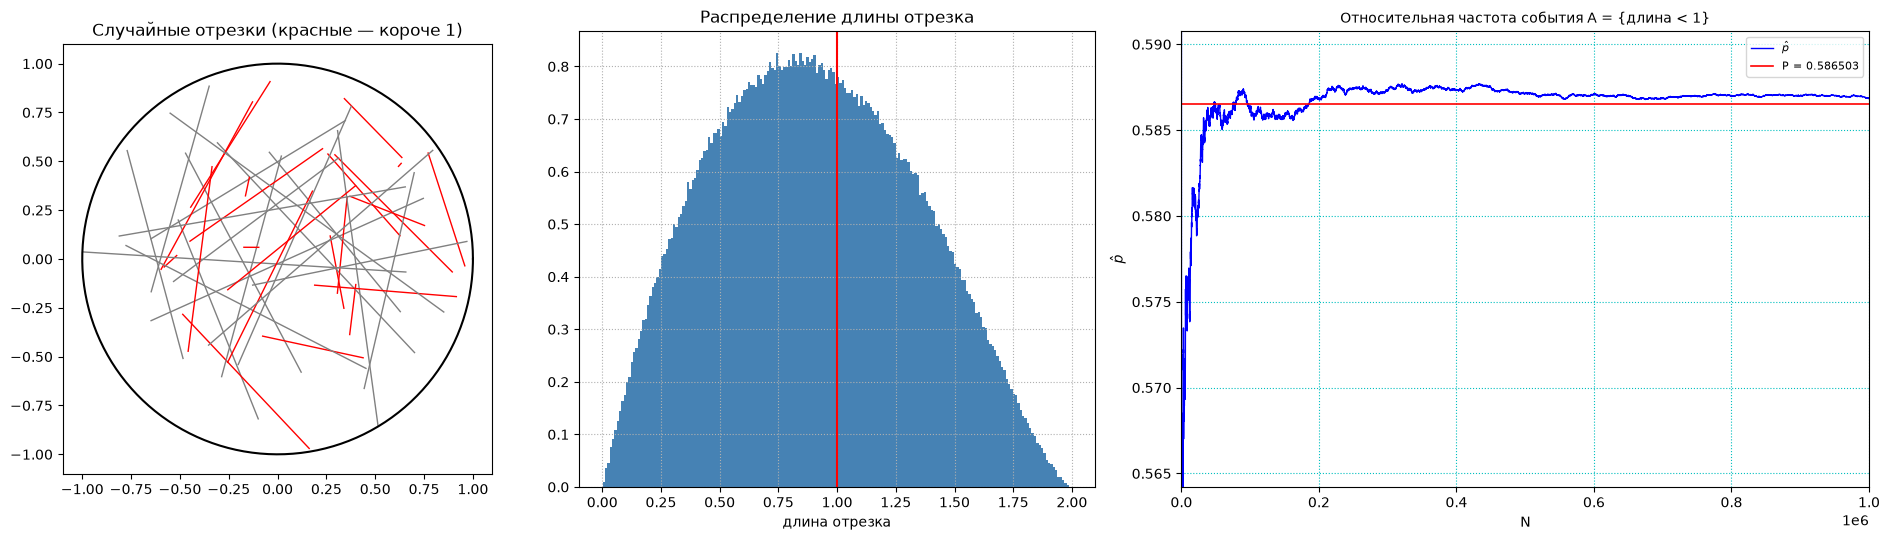

p̂(A) = 0.586858 при N = 1000000;  |p̂ - P| = 3.5e-04


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точная вероятность: P = (2/π) ∫_0^1 ρ S(ρ) dρ ----------
rho = sp.symbols("rho", positive=True)
S = 2*sp.acos(rho/2) - rho/2*sp.sqrt(4 - rho**2)            # площадь линзы
I = sp.simplify(sp.integrate(rho*S, (rho, 0, 1)))
P = sp.simplify(2/sp.pi*I)
print(f"∫ρS(ρ)dρ = {I},  P(A) = {P} = {float(P):.16f}")


def uniform_disk(n):
    """n точек, равномерно распределённых в единичном круге."""
    r = np.sqrt(rng.random(n))
    phi = 2*np.pi*rng.random(n)
    return r*np.cos(phi), r*np.sin(phi)


# ---------- Моделирование ----------
N = 1_000_000
x1, y1 = uniform_disk(N)
x2, y2 = uniform_disk(N)
L = np.hypot(x2 - x1, y2 - y1)          # длина отрезка
hits = L < 1                            # отрезок короче радиуса

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.2, 1.6]})
t = np.linspace(0, 2*np.pi, 300)
for i in range(40):                     # примеры случайных отрезков
    axes[0].plot([x1[i], x2[i]], [y1[i], y2[i]], color="red" if hits[i] else "gray", lw=1)
axes[0].plot(np.cos(t), np.sin(t), "k"); axes[0].set_aspect("equal"); axes[0].set_title("Случайные отрезки (красные — короче 1)")

axes[1].hist(L, bins=200, density=True, color="steelblue")
axes[1].axvline(1, color="red"); axes[1].set_xlabel("длина отрезка"); axes[1].set_title("Распределение длины отрезка")
axes[1].grid(ls=":")

ph = plot_freq(axes[2], hits, float(P), "Относительная частота события A = {длина < 1}")
fig.tight_layout()
plt.show()

print(f"p̂(A) = {ph:.6f} при N = {N};  |p̂ - P| = {abs(ph - float(P)):.1e}")